# Micrograd study



In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def f(x):
    return 3*x**2 - 4*x + 5

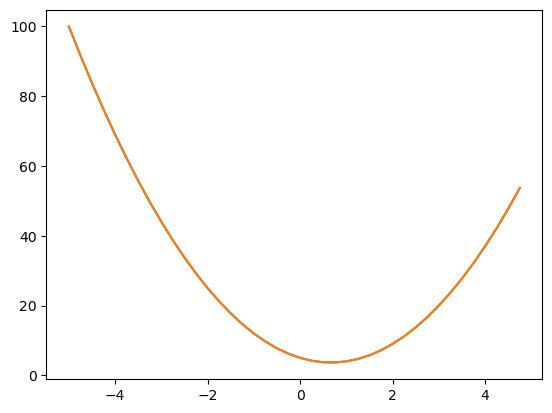

In [8]:
xs = np.arange(-5,5,0.25)
ys = f(xs)
plt.plot(xs, ys)
plt.show()

In [9]:
h = 0.00001
x = 2/3
(f(x + h) - f(x)) / h

3.0000002482211127e-05

In [11]:
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
print(d)

4.0


In [14]:
h = 0.001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
a += h
d2 = a*b + c

print('d1', d1)
print('d2', d2)
print('slope', (d2 - d1) / h)

d1 4.0
d2 3.997
slope -3.0000000000001137


In [225]:
import math


class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out  = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float))
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad
        out._backward = _backward

        return out
        
    def __truediv__(self, other):
        return self * other**-1
    
    def __rmul__(self, other):
        return self * other

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)
        
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward():
            self.grad = out.data * out.grad
        out._backward = _backward

        return out

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [226]:
a = Value(2.0)
b = Value(4.0)
a - b

Value(data=-2.0)

In [118]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges
        

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(
            name = uid,
            label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad),
            shape = 'record'
        )
        if n._op:
            dot.node(name = uid + n._op, label = n._op)
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

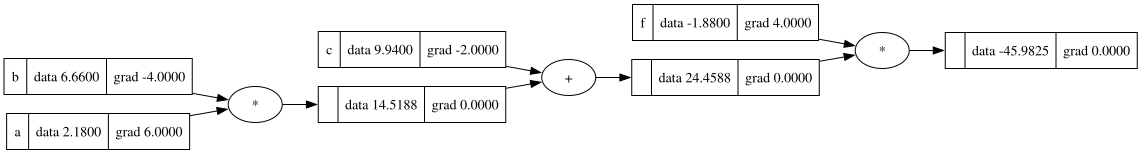

In [129]:
draw_dot(L)

In [227]:
#inputs
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")

# weights
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
# bias
b = Value(6.8813735870195432, label="b")

x1w1 = x1*w1; x1w1.label = "x1*w1"
x2w2 = x2*w2; x2w2.label = "x2*w2"
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = "x1*w1 + x2*w2"
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
o.backward()

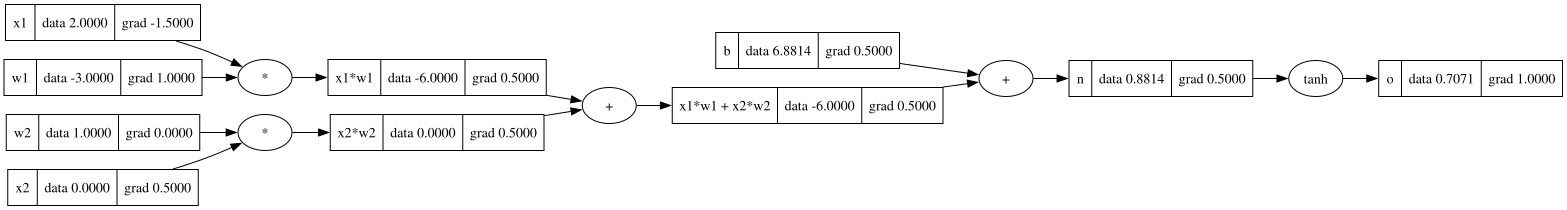

In [228]:
draw_dot(o)

In [229]:
#inputs
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")

# weights
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
# bias
b = Value(6.8813735870195432, label="b")

x1w1 = x1*w1; x1w1.label = "x1*w1"
x2w2 = x2*w2; x2w2.label = "x2*w2"
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = "x1*w1 + x2*w2"
n = x1w1x2w2 + b; n.label = 'n'
# -------
e = (2*n).exp()
o =  (e - 1) / (e + 1)
# -------
; o.label = 'o'
o.backward()

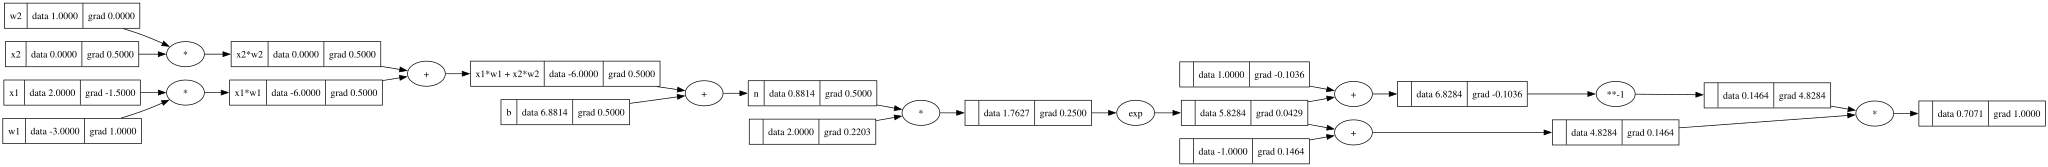

In [230]:
draw_dot(o)

In [231]:
import torch

In [237]:
x1 = torch.tensor([2.0]).double()   ;x1.requires_grad = True
x2 = torch.tensor([0.0]).double()   ;x2.requires_grad = True
w1 = torch.tensor([-3.0]).double()  ;w1.requires_grad = True
w2 = torch.tensor([1.0]).double()   ;w2.requires_grad = True
b = torch.tensor([6.8813735870195432]).double() ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('----')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w2', w2.grad.item())




0.7071066904050358
----
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w2 0.0


In [277]:
import random
class Neuron:

    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        # w*x + b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b) 
        out = act.tanh()
        return out

    def parameters(self):
        return self.w +[self.b]

class Layer:

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]
        

class MLP:

    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]
        


In [454]:
x = [2.0, 3.0 , -1.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=-0.09025270850095653)

In [455]:
len(n.parameters())
n.parameters()

[Value(data=-0.10487684729386904),
 Value(data=-0.6336289072528694),
 Value(data=-0.7327054121971861),
 Value(data=-0.4093227359157847),
 Value(data=-0.9910300772935645),
 Value(data=-0.8293106184635637),
 Value(data=0.026649285845980808),
 Value(data=0.45262144311969976),
 Value(data=-0.6630338545109284),
 Value(data=0.1665967026503925),
 Value(data=0.806695453693254),
 Value(data=0.27253197113322014),
 Value(data=0.2691635430123085),
 Value(data=-0.40484398450558223),
 Value(data=0.5486644734703707),
 Value(data=-0.41541030069657214),
 Value(data=0.06031776628314689),
 Value(data=0.8361859520618788),
 Value(data=-0.9210699203416566),
 Value(data=-0.07537198725736971),
 Value(data=-0.1312360395511174),
 Value(data=0.666437469645669),
 Value(data=0.6905788218457669),
 Value(data=-0.33906015974764747),
 Value(data=-0.15215533049359786),
 Value(data=0.12189415278926652),
 Value(data=0.7743940347310376),
 Value(data=-0.36321243407320236),
 Value(data=0.4360932478935353),
 Value(data=0.973

In [458]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]
ys = [1.0, -1.0, -1.0, -1.0] # targets


In [463]:
for k in range(20):
    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum(((yout - ygt)**2 for ygt, yout in zip(ys, ypred)), Value(0.0))

    # backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    # update
    for p in n.parameters():
        p.data += -0.05 * p.grad

    print(k, loss.data)
    

0 0.023046056293006278
1 0.02263847347294348
2 0.022244358796411935
3 0.02186307062646591
4 0.0214940068867238
5 0.021136602087361504
6 0.020790324613577618
7 0.02045467425003877
8 0.0201291799178138
9 0.019813397602928492
10 0.019506908457974374
11 0.019209317060222473
12 0.018920249811471272
13 0.018639353466423675
14 0.018366293777767596
15 0.018100754247360195
16 0.01784243497399522
17 0.017591051589193427
18 0.017346334273309436
19 0.017108026845006334


In [433]:
ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt, yout in zip(ys, ypred)), Value(0.0))
loss

Value(data=0.03250743828242821)

In [434]:
loss.backward()

In [435]:
for p in n.parameters():
    p.data += -0.01 * p.grad

In [464]:
ypred

[Value(data=0.9131489738049494),
 Value(data=-0.9793995640513905),
 Value(data=-0.9373829270211566),
 Value(data=-0.9277528526226647)]